# BÀI THỰC HÀNH 4: MẠNG NEURAL HỒI QUY

**Môn học:** DS201  
**Họ và tên:** Võ Thụy Sao Mai  
**MSSV:** 24521038

### **PHẦN I. THÀNH PHẦN DÙNG CHUNG**


#### 1. Cấu hình thí nghiệm

In [1]:
from pathlib import Path

import pandas as pd
import torch
from IPython.display import Markdown, display

from src.config import Config, get_device, seed_everything

config = Config()
config.create_output_directories()
seed_everything(config.seed)
device = get_device()

print(config)
print("Device:", device)

Config(project_root=WindowsPath('D:/SaoMai/Documents/UIT/Year3/DS201/Thuc_Hanh/Lab4/Lab4_final'), embedding_dim=256, hidden_size=256, num_layers=3, dropout=0.3, batch_size=32, learning_rate=0.001, teacher_forcing_ratio=0.5, max_epochs=10, gradient_clip=1.0, max_words=50, vocab_limit=10000, min_frequency=2, max_decode_steps=51, seed=42, num_workers=0)
Device: cuda


#### 2. Chuẩn bị dữ liệu small-PhoMT

In [2]:
from src.data import BOS_ID, EOS_ID, PAD_ID, UNK_ID, prepare_data

data = prepare_data(config)
print("Số lượng:", data.counts)
print("Source vocabulary:", len(data.source_vocab))
print("Target vocabulary:", len(data.target_vocab))

assert data.counts["train"]["filtered"] == 18607
assert data.counts["dev"]["filtered"] == 1901
assert data.counts["test"]["filtered"] == 1786
assert len(data.source_vocab) == 8943
assert len(data.target_vocab) == 4003
print("Dữ liệu và vocabulary: PASS")

Số lượng: {'train': {'raw': 20000, 'filtered': 18607}, 'dev': {'raw': 2000, 'filtered': 1901}, 'test': {'raw': 2000, 'filtered': 1786}}
Source vocabulary: 8943
Target vocabulary: 4003
Dữ liệu và vocabulary: PASS


In [3]:
train_loader = data.create_loader(
    "train", config.batch_size, shuffle=True,
    seed=config.seed, num_workers=config.num_workers,
)
sample_batch = next(iter(train_loader))
print("Source:", tuple(sample_batch.source.shape))
print("Lengths:", tuple(sample_batch.source_lengths.shape))
print("Target:", tuple(sample_batch.target.shape))
assert torch.all(sample_batch.target[:, 0] == BOS_ID)
print("Batch và nhãn dịch một bước: PASS")

Source: (32, 47)
Lengths: (32,)
Target: (32, 50)
Batch và nhãn dịch một bước: PASS


#### 3. Hàm dùng chung để báo cáo kết quả


In [4]:
from src.models import build_model, count_parameters
from src.train_eval import evaluate, fit, rouge_l, write_csv
from src.visualization import plot_attention_heatmap, plot_training_history


def evaluate_test(model):
    loader = data.create_loader(
        "test", config.batch_size, shuffle=False,
        seed=config.seed, num_workers=config.num_workers,
    )
    return evaluate(
        model, loader, data.target_vocab,
        device, config.max_decode_steps,
    )


def print_metrics(result):
    print(f"Test NLL: {result.nll:.4f}")
    print(f"Test ROUGE-L Precision: {result.rougeL_precision:.4f}")
    print(f"Test ROUGE-L Recall: {result.rougeL_recall:.4f}")
    print(f"Test ROUGE-L F1: {result.rougeL_f1:.4f}")


def select_examples(result, output_name):
    ordered = sorted(result.predictions, key=lambda row: row["rougeL_f1"])
    positions = [0, len(ordered) // 2, len(ordered) - 1]
    labels = ["Ví dụ điểm thấp", "Ví dụ trung vị", "Ví dụ điểm cao"]
    source_by_id = {
        row.row_id: " ".join(row.source_tokens)
        for row in data.test_rows
    }
    examples = []
    for label, position in zip(labels, positions):
        row = ordered[position]
        example = {
            "label": label,
            "row_id": row["row_id"],
            "source": source_by_id[int(row["row_id"])],
            "reference": row["reference"],
            "hypothesis": row["hypothesis"],
            "rougeL_f1": row["rougeL_f1"],
        }
        examples.append(example)
        print(label)
        print("EN :", example["source"])
        print("REF:", example["reference"])
        print("HYP:", example["hypothesis"])
        print(f"ROUGE-L: {example['rougeL_f1']:.4f}\n")
    write_csv(config.artifact_dir / "tables" / output_name, examples)
    return examples


assert rouge_l("tiếng việt có dấu", "tiếng việt có dấu").fmeasure == 1.0
print("ROUGE-L tiếng Việt: PASS")

ROUGE-L tiếng Việt: PASS


### **PHẦN II. BÀI TẬP VỀ NHÀ**

#### **Bài 1.** Xây dựng kiến trúc Encoder-Decoder gồm 3 lớp LSTM cho module encoder và 3 lớp LSTM cho module decoder, với hidden size là 256, cho bài toán dịch máy từ tiếng Anh sang tiếng Việt. Huấn luyện mô hình này trên bộ dữ liệu PhoMT sử dụng Adam làm phương thức tối ưu tham số. Đánh giá độ hiệu quả của mô hình sử dụng độ đo ROUGE-L.

**1. Kiểm tra kiến trúc baseline**

In [5]:
seed_everything(config.seed)
check_bai1 = build_model(
    "none", len(data.source_vocab), len(data.target_vocab), config
).to(device)
batch = sample_batch.to(device)
check_bai1.eval()
with torch.no_grad():
    memory, (hidden, cell) = check_bai1.encoder(batch.source, batch.source_lengths)

print("Số tham số:", f"{count_parameters(check_bai1):,}")
print("Memory:", tuple(memory.shape))
print("Hidden/Cell:", tuple(hidden.shape), tuple(cell.shape))
assert count_parameters(check_bai1) == 7_500_963
assert hidden.shape[0] == cell.shape[0] == config.num_layers
print("Kiến trúc baseline: PASS")
del check_bai1

Số tham số: 7,500,963
Memory: (32, 47, 256)
Hidden/Cell: (3, 32, 256) (3, 32, 256)
Kiến trúc baseline: PASS


**2. Huấn luyện và learning curve**


In [6]:
seed_everything(config.seed)
model_bai1 = build_model(
    "none", len(data.source_vocab), len(data.target_vocab), config
).to(device)
history_bai1, best_epoch_bai1 = fit(
    model_bai1, data, config, device, "bai1_baseline"
)
print("Epoch tốt nhất:", best_epoch_bai1)

Epoch 01/10 | train_loss=6.0181 | dev_nll=5.8932 | dev_ROUGE-L=0.1291 | 181.1s
  -> Đã lưu checkpoint tốt nhất
Epoch 02/10 | train_loss=5.7020 | dev_nll=5.6017 | dev_ROUGE-L=0.1601 | 122.0s
  -> Đã lưu checkpoint tốt nhất
Epoch 03/10 | train_loss=5.5110 | dev_nll=5.3966 | dev_ROUGE-L=0.1830 | 127.3s
  -> Đã lưu checkpoint tốt nhất
Epoch 04/10 | train_loss=5.3769 | dev_nll=5.2564 | dev_ROUGE-L=0.1941 | 121.8s
  -> Đã lưu checkpoint tốt nhất
Epoch 05/10 | train_loss=5.2640 | dev_nll=5.1497 | dev_ROUGE-L=0.2069 | 110.7s
  -> Đã lưu checkpoint tốt nhất
Epoch 06/10 | train_loss=5.1705 | dev_nll=5.0539 | dev_ROUGE-L=0.2148 | 103.5s
  -> Đã lưu checkpoint tốt nhất
Epoch 07/10 | train_loss=5.0867 | dev_nll=4.9863 | dev_ROUGE-L=0.2148 | 97.6s
  -> Đã lưu checkpoint tốt nhất
Epoch 08/10 | train_loss=5.0156 | dev_nll=4.9178 | dev_ROUGE-L=0.2195 | 117.8s
  -> Đã lưu checkpoint tốt nhất
Epoch 09/10 | train_loss=4.9485 | dev_nll=4.8417 | dev_ROUGE-L=0.2275 | 118.4s
  -> Đã lưu checkpoint tốt nhất
Ep

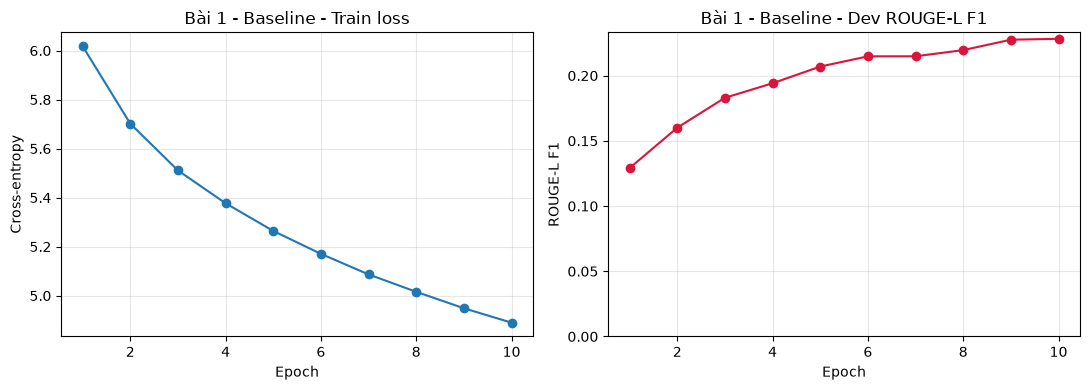

,epoch,train_loss,dev_nll,dev_rougeL,seconds
0,1,6.018120,5.893200,0.129125,181.145044
1,2,5.701973,5.601662,0.160075,122.024071
2,3,5.511047,5.396575,0.182989,127.292037
3,4,5.376943,5.256381,0.194132,121.800707
4,5,5.264030,5.149662,0.206923,110.725955
5,6,5.170538,5.053929,0.214758,103.540645
6,7,5.086655,4.986330,0.214816,97.629775
7,8,5.015643,4.917812,0.219533,117.826606
8,9,4.948459,4.841741,0.227516,118.351003
9,10,4.889682,4.800782,0.228212,119.811541


In [7]:
plot_training_history(
    history_bai1,
    config.artifact_dir / "figures" / "bai1_learning_curves.png",
    "Bài 1 - Baseline",
)
pd.DataFrame(history_bai1)

**3. Kết quả test và ba câu dịch mẫu**

In [8]:
test_bai1 = evaluate_test(model_bai1)
print_metrics(test_bai1)
write_csv(
    config.artifact_dir / "tables" / "bai1_test_predictions.csv",
    test_bai1.predictions,
)
examples_bai1 = select_examples(test_bai1, "bai1_examples.csv")

Test NLL: 4.6827
Test ROUGE-L Precision: 0.2644
Test ROUGE-L Recall: 0.2146
Test ROUGE-L F1: 0.2352
Ví dụ điểm thấp
EN : v - pop prince 's documentary soundtrack among global music charts
REF: nhạc phim tài liệu của hoàng tử v-pop lọt vào các bảng xếp hạng âm nhạc toàn cầu
HYP: <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> .
ROUGE-L: 0.0000

Ví dụ trung vị
EN : so let 's take the first example , not knowing who we 're dealing with .
REF: ví dụ , việc không biết người mình đang giao dịch là ai .
HYP: hãy hãy hãy hãy , , , , không có gì chúng ta .
ROUGE-L: 0.2143

Ví dụ điểm cao
EN : ( applause )
REF: ( vỗ tay )
HYP: ( vỗ tay )
ROUGE-L: 1.0000



In [10]:
model_bai1.to("cpu")
if torch.cuda.is_available():
    torch.cuda.empty_cache()

**Nhận xét Bài 1**

Sau 10 epoch huấn luyện, train loss giảm đều từ 6.0181 xuống 4.8897, trong khi dev ROUGE-L F1 tăng từ 0.1291 lên 0.2282. Điều này cho thấy mô hình đã học được mối liên hệ cơ bản giữa câu nguồn tiếng Anh và câu đích tiếng Việt, đồng thời chưa xuất hiện dấu hiệu overfitting rõ rệt trong phạm vi số epoch đã chạy. Trên tập test, mô hình đạt NLL là 4.6827 và ROUGE-L F1 là 0.2352.

Qua các câu dịch mẫu, mô hình có thể dịch chính xác một số câu rất ngắn như “( applause )” thành “( vỗ tay )”. Tuy nhiên, với câu dài hoặc chứa tên riêng và từ hiếm, kết quả thường xuất hiện nhiều token `<unk>`, thiếu nội dung hoặc lặp từ. Nguyên nhân chính là toàn bộ thông tin của câu nguồn phải được nén vào trạng thái cuối của encoder nên decoder khó ghi nhớ đầy đủ câu dài. Vì vậy, kết quả của Bài 1 được sử dụng làm baseline để đánh giá mức cải thiện của các mô hình có attention ở hai bài tiếp theo.

#### **Bài 2.** Xây dựng kiến trúc Encoder-Decoder gồm 3 lớp LSTM cho module encoder và 3 lớp LSTM cho module decoder, với hidden size là 256, cho bài toán dịch máy từ tiếng Anh sang tiếng Việt. Module decoder được trang bị kỹ thuật attention theo mô tả của nghiên cứu "[Neural Machine Translation by Jointly Learning to Align and Translate](https://arxiv.org/abs/1409.0473)". Huấn luyện mô hình này trên bộ dữ liệu PhoMT sử dụng Adam làm phương thức tối ưu tham số. Đánh giá độ hiệu quả của mô hình sử dụn độ đo ROUGE-L.

**1. Kiểm tra kiến trúc và attention mask**

In [11]:
seed_everything(config.seed)
check_bai2 = build_model(
    "bahdanau", len(data.source_vocab), len(data.target_vocab), config
).to(device)
batch = sample_batch.to(device)
check_bai2.eval()
with torch.no_grad():
    logits, attention = check_bai2(
        batch.source, batch.source_lengths, batch.target,
        teacher_forcing_ratio=1.0, return_attention=True,
    )

print("Số tham số:", f"{count_parameters(check_bai2):,}")
print("Logits:", tuple(logits.shape))
print("Attention:", tuple(attention.shape))
assert count_parameters(check_bai2) == 8_025_763
assert logits.shape[:2] == batch.target[:, 1:].shape
torch.testing.assert_close(attention.sum(-1), torch.ones_like(attention.sum(-1)))
padding = (~(batch.source != PAD_ID).unsqueeze(1)).expand_as(attention)
assert torch.all(attention.masked_select(padding) == 0)
print("Bahdanau shape và mask: PASS")
del check_bai2

Số tham số: 8,025,763
Logits: (32, 49, 4003)
Attention: (32, 49, 47)
Bahdanau shape và mask: PASS


**2. Huấn luyện và learning curve**

In [12]:
seed_everything(config.seed)
model_bai2 = build_model(
    "bahdanau", len(data.source_vocab), len(data.target_vocab), config
).to(device)
history_bai2, best_epoch_bai2 = fit(
    model_bai2, data, config, device, "bai2_bahdanau"
)
print("Epoch tốt nhất:", best_epoch_bai2)

Epoch 01/10 | train_loss=6.0414 | dev_nll=5.9114 | dev_ROUGE-L=0.1393 | 201.2s
  -> Đã lưu checkpoint tốt nhất
Epoch 02/10 | train_loss=5.6504 | dev_nll=5.5013 | dev_ROUGE-L=0.1970 | 186.8s
  -> Đã lưu checkpoint tốt nhất
Epoch 03/10 | train_loss=5.3626 | dev_nll=5.2253 | dev_ROUGE-L=0.2224 | 209.4s
  -> Đã lưu checkpoint tốt nhất
Epoch 04/10 | train_loss=5.1611 | dev_nll=5.0312 | dev_ROUGE-L=0.2456 | 194.6s
  -> Đã lưu checkpoint tốt nhất
Epoch 05/10 | train_loss=4.9986 | dev_nll=4.9016 | dev_ROUGE-L=0.2512 | 186.4s
  -> Đã lưu checkpoint tốt nhất
Epoch 06/10 | train_loss=4.8655 | dev_nll=4.7923 | dev_ROUGE-L=0.2662 | 193.9s
  -> Đã lưu checkpoint tốt nhất
Epoch 07/10 | train_loss=4.7533 | dev_nll=4.6905 | dev_ROUGE-L=0.2748 | 181.8s
  -> Đã lưu checkpoint tốt nhất
Epoch 08/10 | train_loss=4.6542 | dev_nll=4.6156 | dev_ROUGE-L=0.2843 | 185.4s
  -> Đã lưu checkpoint tốt nhất
Epoch 09/10 | train_loss=4.5660 | dev_nll=4.5426 | dev_ROUGE-L=0.2942 | 195.1s
  -> Đã lưu checkpoint tốt nhất
E

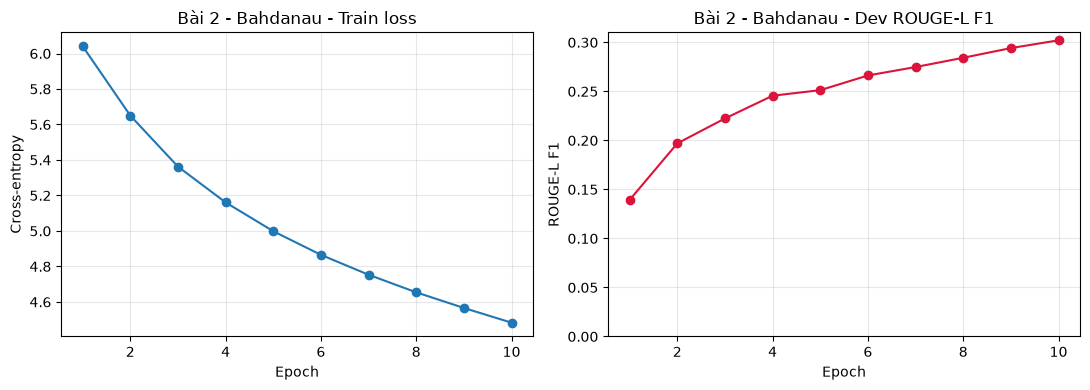

,epoch,train_loss,dev_nll,dev_rougeL,seconds
0,1,6.041393,5.911412,0.139276,201.242435
1,2,5.650386,5.501337,0.196951,186.817941
2,3,5.362593,5.225321,0.222375,209.361014
3,4,5.161082,5.031217,0.245588,194.582083
4,5,4.998574,4.901633,0.251244,186.424239
5,6,4.865456,4.792251,0.266238,193.904117
6,7,4.753268,4.690496,0.274834,181.813692
7,8,4.654210,4.615572,0.284282,185.415361
8,9,4.566004,4.542602,0.294163,195.132945
9,10,4.483207,4.493107,0.302093,181.226128


In [13]:
plot_training_history(
    history_bai2,
    config.artifact_dir / "figures" / "bai2_learning_curves.png",
    "Bài 2 - Bahdanau",
)
pd.DataFrame(history_bai2)

**3. Kết quả test, câu dịch mẫu và heatmap**

In [14]:
test_bai2 = evaluate_test(model_bai2)
print_metrics(test_bai2)
write_csv(
    config.artifact_dir / "tables" / "bai2_test_predictions.csv",
    test_bai2.predictions,
)
examples_bai2 = select_examples(test_bai2, "bai2_examples.csv")

Test NLL: 4.3430
Test ROUGE-L Precision: 0.3404
Test ROUGE-L Recall: 0.2958
Test ROUGE-L F1: 0.3142
Ví dụ điểm thấp
EN : v - pop prince 's documentary soundtrack among global music charts
REF: nhạc phim tài liệu của hoàng tử v-pop lọt vào các bảng xếp hạng âm nhạc toàn cầu
HYP: <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> .
ROUGE-L: 0.0000

Ví dụ trung vị
EN : light is electromagnetic radiation that acts like both a wave and a particle .
REF: ánh sáng là bức xạ điện từ có đồng thời biểu hiện của sóng và hạt .
HYP: ánh sáng là được tạo ra những giống như như một người và và một một .
ROUGE-L: 0.2941

Ví dụ điểm cao
EN : ( applause )
REF: ( vỗ tay )
HYP: ( vỗ tay )
ROUGE-L: 1.0000



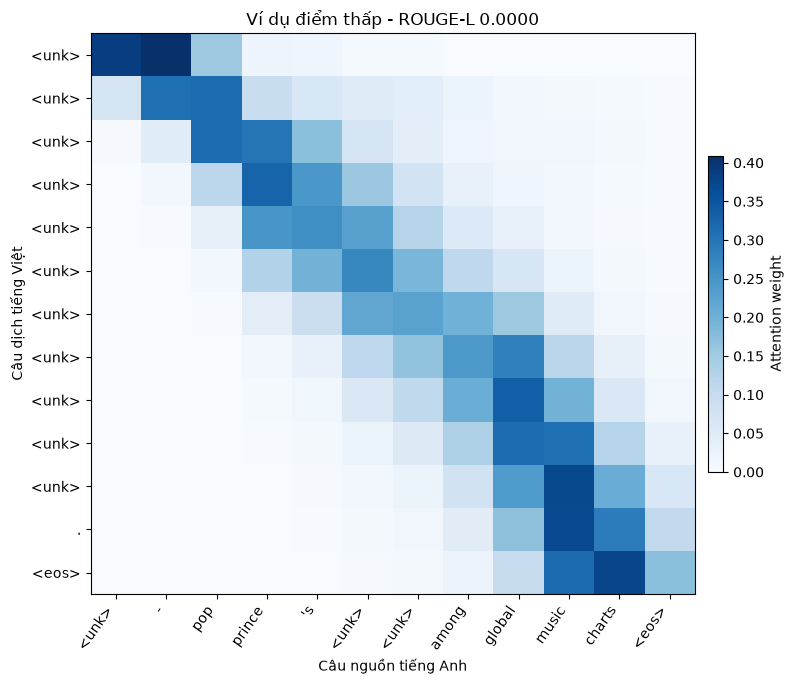

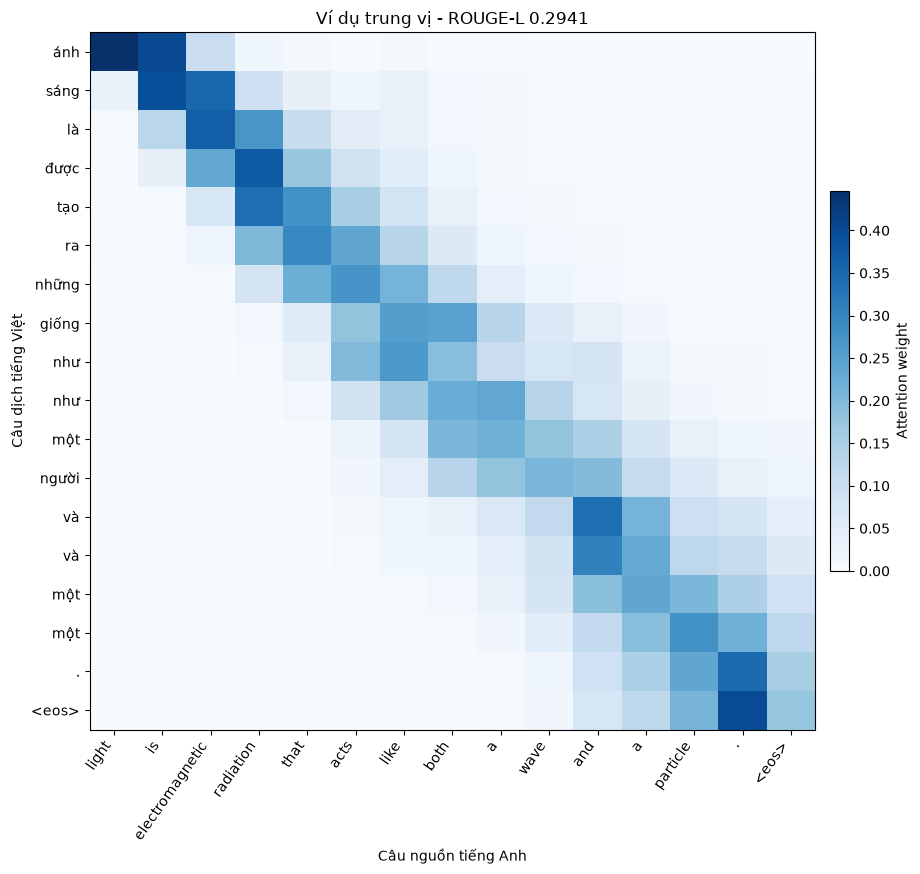

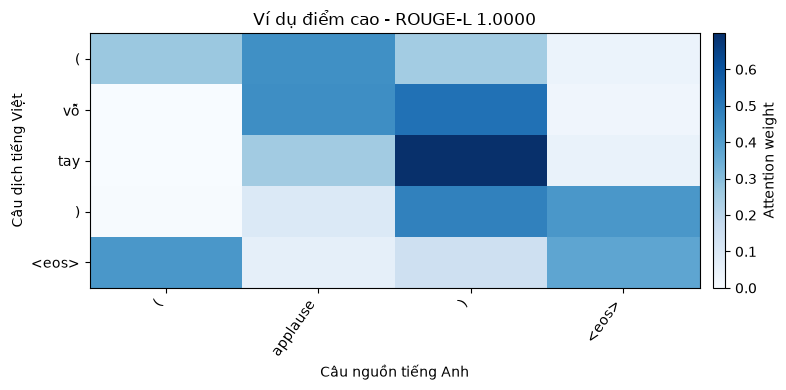

In [15]:
from src.train_eval import translate_with_attention

test_rows_by_id = {row.row_id: row for row in data.test_rows}
heatmap_names = ["low", "median", "high"]
for example, name in zip(examples_bai2, heatmap_names):
    translated = translate_with_attention(
        model_bai2,
        test_rows_by_id[int(example["row_id"])],
        data.source_vocab,
        data.target_vocab,
        device,
        config.max_decode_steps,
    )
    assert translated["hypothesis"] == example["hypothesis"]
    plot_attention_heatmap(
        translated["attention"],
        translated["source_tokens"],
        translated["output_tokens"],
        f"{example['label']} - ROUGE-L {example['rougeL_f1']:.4f}",
        config.artifact_dir / "figures" / f"bai2_attention_{name}.png",
    )

In [17]:
model_bai2.to("cpu")
if torch.cuda.is_available():
    torch.cuda.empty_cache()

**Nhận xét Bài 2** 

Sau 10 epoch, train loss của mô hình Bahdanau Attention giảm từ 6.0414 xuống 4.4832 và dev ROUGE-L F1 tăng liên tục lên 0.3021. Trên tập test, mô hình đạt NLL là 4.3430, precision 0.3404, recall 0.2958 và ROUGE-L F1 là 0.3142. So với baseline, test F1 tăng từ 0.2352 lên 0.3142, tương đương mức cải thiện khoảng 33.6%. Kết quả này cho thấy cơ chế attention giúp decoder khai thác thông tin từ toàn bộ các trạng thái của encoder tốt hơn so với việc chỉ sử dụng trạng thái cuối.

Các attention heatmap cho thấy vùng tập trung có xu hướng dịch chuyển từ đầu đến cuối câu nguồn khi decoder lần lượt sinh các token tiếng Việt. Ở ví dụ trung vị, mô hình đã dịch đúng được một số phần như “ánh sáng là”, nhưng phần sau vẫn sai nghĩa và xuất hiện hiện tượng lặp từ. Đối với câu chứa nhiều từ hiếm, mô hình vẫn sinh nhiều `<unk>`, vì attention chỉ hỗ trợ lựa chọn thông tin nguồn chứ không giải quyết được giới hạn của vocabulary. Nhìn chung, Bahdanau Attention cải thiện rõ rệt chất lượng bản dịch, nhưng khả năng chọn từ và độ trôi chảy của câu vẫn còn hạn chế.

#### **Bài 3.** Xây dựng kiến trúc Encoder-Decoder gồm 3 lớp LSTM cho module encoder và 3 lớp LSTM cho module decoder, với hidden size là 256, cho bài toán dịch máy từ tiếng Anh sang tiếng Việt. Module decoder được trang bị kỹ thuật attention theo mô tả của nghiên cứu "[Effective Approaches to Attention-based Neural Machine Translation](https://arxiv.org/abs/1508.04025)". Huấn luyện mô hình này trên bộ dữ liệu PhoMT sử dụng Adam làm phương thức tối ưu tham số. Đánh giá độ hiệu quả của mô hình sử dụn độ đo ROUGE-L.


**1. Kiểm tra kiến trúc Luong**

In [18]:
seed_everything(config.seed)
check_bai3 = build_model(
    "luong", len(data.source_vocab), len(data.target_vocab), config
).to(device)
batch = sample_batch.to(device)
check_bai3.eval()
with torch.no_grad():
    logits, attention = check_bai3(
        batch.source, batch.source_lengths, batch.target,
        teacher_forcing_ratio=1.0, return_attention=True,
    )

print("Số tham số:", f"{count_parameters(check_bai3):,}")
print("LSTM input size:", check_bai3.decoder.lstm.input_size)
print("Logits:", tuple(logits.shape))
print("Attention:", tuple(attention.shape))
assert count_parameters(check_bai3) == 7_959_971
assert check_bai3.decoder.lstm.input_size == config.embedding_dim + config.hidden_size
assert logits.shape[:2] == batch.target[:, 1:].shape
torch.testing.assert_close(attention.sum(-1), torch.ones_like(attention.sum(-1)))
print("Luong general và input-feeding: PASS")
del check_bai3

Số tham số: 7,959,971
LSTM input size: 512
Logits: (32, 49, 4003)
Attention: (32, 49, 47)
Luong general và input-feeding: PASS


**2. Huấn luyện và learning curve**

In [19]:
seed_everything(config.seed)
model_bai3 = build_model(
    "luong", len(data.source_vocab), len(data.target_vocab), config
).to(device)
history_bai3, best_epoch_bai3 = fit(
    model_bai3, data, config, device, "bai3_luong"
)
print("Epoch tốt nhất:", best_epoch_bai3)

Epoch 01/10 | train_loss=6.0712 | dev_nll=5.9786 | dev_ROUGE-L=0.1243 | 184.0s
  -> Đã lưu checkpoint tốt nhất
Epoch 02/10 | train_loss=5.7240 | dev_nll=5.5896 | dev_ROUGE-L=0.1852 | 159.9s
  -> Đã lưu checkpoint tốt nhất
Epoch 03/10 | train_loss=5.4424 | dev_nll=5.3139 | dev_ROUGE-L=0.2112 | 170.6s
  -> Đã lưu checkpoint tốt nhất
Epoch 04/10 | train_loss=5.2271 | dev_nll=5.0996 | dev_ROUGE-L=0.2388 | 190.2s
  -> Đã lưu checkpoint tốt nhất
Epoch 05/10 | train_loss=5.0520 | dev_nll=4.9346 | dev_ROUGE-L=0.2440 | 185.8s
  -> Đã lưu checkpoint tốt nhất
Epoch 06/10 | train_loss=4.9052 | dev_nll=4.8047 | dev_ROUGE-L=0.2615 | 198.3s
  -> Đã lưu checkpoint tốt nhất
Epoch 07/10 | train_loss=4.7832 | dev_nll=4.7095 | dev_ROUGE-L=0.2744 | 201.1s
  -> Đã lưu checkpoint tốt nhất
Epoch 08/10 | train_loss=4.6738 | dev_nll=4.6109 | dev_ROUGE-L=0.2831 | 173.1s
  -> Đã lưu checkpoint tốt nhất
Epoch 09/10 | train_loss=4.5781 | dev_nll=4.5345 | dev_ROUGE-L=0.2966 | 186.6s
  -> Đã lưu checkpoint tốt nhất
E

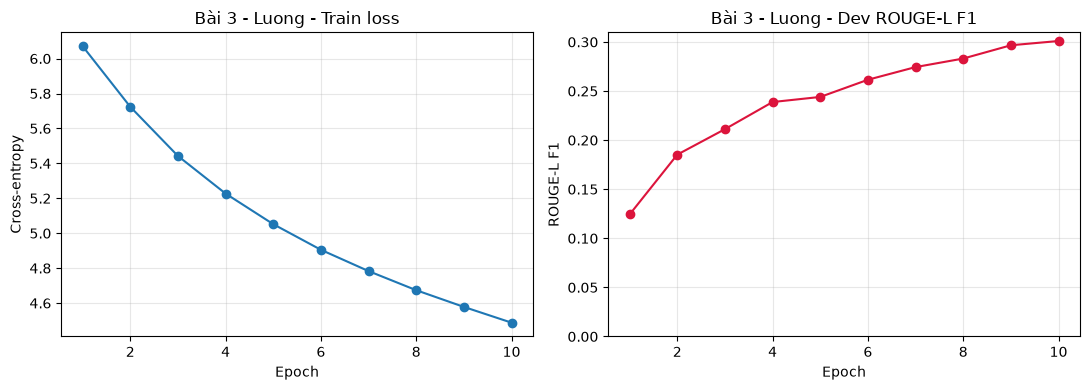

,epoch,train_loss,dev_nll,dev_rougeL,seconds
0,1,6.071172,5.978587,0.124284,183.979327
1,2,5.723974,5.589650,0.185230,159.926089
2,3,5.442384,5.313941,0.211179,170.561493
3,4,5.227100,5.099567,0.238810,190.227392
4,5,5.051979,4.934589,0.244001,185.765921
5,6,4.905155,4.804725,0.261510,198.286230
6,7,4.783203,4.709531,0.274415,201.053614
7,8,4.673790,4.610947,0.283108,173.144164
8,9,4.578125,4.534498,0.296629,186.569851
9,10,4.487927,4.462739,0.300970,186.956677


In [20]:
plot_training_history(
    history_bai3,
    config.artifact_dir / "figures" / "bai3_learning_curves.png",
    "Bài 3 - Luong",
)
pd.DataFrame(history_bai3)

**3. Kết quả test và ba câu dịch mẫu**

In [21]:
test_bai3 = evaluate_test(model_bai3)
print_metrics(test_bai3)
write_csv(
    config.artifact_dir / "tables" / "bai3_test_predictions.csv",
    test_bai3.predictions,
)
examples_bai3 = select_examples(test_bai3, "bai3_examples.csv")

Test NLL: 4.3126
Test ROUGE-L Precision: 0.3445
Test ROUGE-L Recall: 0.2957
Test ROUGE-L F1: 0.3158
Ví dụ điểm thấp
EN : lifetime employment for public employees abolished from today
REF: bãi bỏ viên chức suốt đời cho cán bộ nhà nước từ hôm nay
HYP: mỗi người với với với các năm .
ROUGE-L: 0.0000

Ví dụ trung vị
EN : but you might not know that there are 20 space telescopes in orbit , missions that can each see part of the full spectrum of light .
REF: nhưng bạn chưa biết rằng có 20 kính thiên văn trong quỹ đạo có nhiệm vụ là nhìn từng phần của cả dãy quang phổ .
HYP: nhưng bạn có biết biết rằng có có có có có trong trong , , có thể thấy thấy có thể thấy thấy một trong những trong .
ROUGE-L: 0.2963

Ví dụ điểm cao
EN : do n't worry .
REF: đừng lo lắng .
HYP: đừng lo lắng .
ROUGE-L: 1.0000



**4. So sánh ba mô hình**

In [22]:
def best_dev(history):
    return sorted(
        history,
        key=lambda row: (row["dev_rougeL"], -row["dev_nll"]),
        reverse=True,
    )[0]["dev_rougeL"]


comparison = pd.DataFrame([
    {
        "Mô hình": "Bài 1. Không attention",
        "ROUGE-L dev": best_dev(history_bai1),
        "ROUGE-L test": test_bai1.rougeL_f1,
        "Số tham số": count_parameters(model_bai1),
        "Giây/epoch": pd.DataFrame(history_bai1)["seconds"].mean(),
    },
    {
        "Mô hình": "Bài 2. Bahdanau",
        "ROUGE-L dev": best_dev(history_bai2),
        "ROUGE-L test": test_bai2.rougeL_f1,
        "Số tham số": count_parameters(model_bai2),
        "Giây/epoch": pd.DataFrame(history_bai2)["seconds"].mean(),
    },
    {
        "Mô hình": "Bài 3. Luong",
        "ROUGE-L dev": best_dev(history_bai3),
        "ROUGE-L test": test_bai3.rougeL_f1,
        "Số tham số": count_parameters(model_bai3),
        "Giây/epoch": pd.DataFrame(history_bai3)["seconds"].mean(),
    },
])
comparison.to_csv(
    config.artifact_dir / "tables" / "comparison_models.csv",
    index=False,
    encoding="utf-8-sig",
)
comparison.round({"ROUGE-L dev": 4, "ROUGE-L test": 4, "Giây/epoch": 2})

,Mô hình,ROUGE-L dev,ROUGE-L test,Số tham số,Giây/epoch
0,Bài 1. Không attention,0.2282,0.2352,7500963,122.01
1,Bài 2. Bahdanau,0.3021,0.3142,8025763,191.59
2,Bài 3. Luong,0.3010,0.3158,7959971,183.65


**Nhận xét Bài 3** 

Mô hình Luong global-general Attention có train loss giảm từ 6.0712 xuống 4.4879 và dev ROUGE-L F1 tăng lên 0.3010 sau 10 epoch. Trên tập test, mô hình đạt NLL thấp nhất là 4.3126, precision 0.3445, recall 0.2957 và ROUGE-L F1 cao nhất là 0.3158. So với baseline, test F1 tăng 0.0806 điểm, tương đương khoảng 34.3%. Kết quả cho thấy Luong Attention cũng khắc phục được một phần hạn chế của mô hình Encoder–Decoder không sử dụng attention.

Ở các câu dịch mẫu, mô hình dịch chính xác câu ngắn “do n't worry .” thành “đừng lo lắng .”. Tuy nhiên, với câu dài hơn, mô hình chỉ giữ được một số cụm từ đúng và vẫn xuất hiện tình trạng lặp từ hoặc lựa chọn nội dung chưa chính xác. So với Bahdanau Attention, Luong đạt test F1 cao hơn 0.0016 và có thời gian huấn luyện mỗi epoch thấp hơn, nhưng mức chênh lệch chất lượng là rất nhỏ. Vì thí nghiệm chỉ sử dụng một seed, chưa thể khẳng định Luong vượt trội hoàn toàn. Trong phạm vi Lab 4, Luong Attention là mô hình có kết quả test tốt nhất, còn hai mô hình attention nhìn chung đều hiệu quả hơn rõ rệt so với baseline.

### **PHẦN III. KIỂM TRA FILE ĐẦU RA**

In [24]:
expected_files = [
    config.checkpoint_dir / "bai1_baseline.pt",
    config.checkpoint_dir / "bai2_bahdanau.pt",
    config.checkpoint_dir / "bai3_luong.pt",
    config.artifact_dir / "figures" / "bai1_learning_curves.png",
    config.artifact_dir / "figures" / "bai2_learning_curves.png",
    config.artifact_dir / "figures" / "bai3_learning_curves.png",
    config.artifact_dir / "figures" / "bai2_attention_low.png",
    config.artifact_dir / "figures" / "bai2_attention_median.png",
    config.artifact_dir / "figures" / "bai2_attention_high.png",
    config.artifact_dir / "tables" / "comparison_models.csv",
]
for path in expected_files:
    print(f"{'OK' if path.exists() else 'MISSING':7} - {path.name}")
assert all(path.exists() for path in expected_files)
print("Toàn bộ đầu ra Lab 4: PASS")

OK      - bai1_baseline.pt
OK      - bai2_bahdanau.pt
OK      - bai3_luong.pt
OK      - bai1_learning_curves.png
OK      - bai2_learning_curves.png
OK      - bai3_learning_curves.png
OK      - bai2_attention_low.png
OK      - bai2_attention_median.png
OK      - bai2_attention_high.png
OK      - comparison_models.csv
Toàn bộ đầu ra Lab 4: PASS
